# Results of the dissertation, from the files in `results/`

This notebook rebuilds the main tables and figures of the evaluation (dissertation,
Sections 5.6, 6.3, and 7.2) **without training anything and without the dataset**:
it only reads the outputs of the pipeline stored in `results/`.
The last section, optional, loads a trained model (requires PyTorch).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results"
SENSORS = {"adxl": "ADXL345", "piezo": "Piezoelectric", "mpu": "MPU9250"}

## Table 6.3 - health estimation on the held-out test sequences

In [2]:
m = json.loads((RES / "metrics.json").read_text())
pd.DataFrame({SENSORS[s]: {"HI RMSE": v["rmse"], "HI MAE": v["mae"],
                           "RUL RMSE after FPT (h)": v["rul_rmse_h"],
                           "RUL MAE after FPT (h)": v["rul_mae_h"],
                           "test sequences": v["n_test"], "parameters": v["n_params"]}
              for s, v in m.items()}).T.round(4)

,HI RMSE,HI MAE,RUL RMSE after FPT (h),RUL MAE after FPT (h),test sequences,parameters
ADXL345,0.0492,0.0292,0.7183,0.4934,192.0,205313.0
Piezoelectric,0.0412,0.0294,0.8268,0.5717,248.0,52097.0
MPU9250,0.0840,0.0472,1.5519,0.9328,246.0,564609.0


## Table 6.4 - comparison with simpler regressors (HI RMSE / MAE)

In [3]:
b = pd.read_csv(RES / "baselines.csv")
b["sensor"] = b["sensor"].map(SENSORS)
b.pivot(index="model", columns="sensor", values=["rmse", "mae"]).round(4)

rmse                           mae          \
sensor                      ADXL345 MPU9250 Piezoelectric ADXL345 MPU9250   
model                                                                       
CNN-BiLSTM                   0.0492  0.0840        0.0412  0.0292  0.0472   
RMS-based linear regression  0.2726  0.2322        0.2231  0.2256  0.1775   
Random forest                0.1324  0.1197        0.0486  0.0650  0.0719   
Ridge regression             0.1750  0.1766        0.1303  0.1379  0.1372   

                                           
sensor                      Piezoelectric  
model                                      
CNN-BiLSTM                         0.0294  
RMS-based linear regression        0.1849  
Random forest                      0.0307  
Ridge regression                   0.1024

## Table 6.5 - errors with whole sessions held out

The block split puts windows of every session in training and test; holding out whole
sessions (five interleaved groups) is closer to a new degradation run.

In [4]:
rows = {}
for s, name in SENSORS.items():
    d = json.loads((RES / f"loso_{s}.json").read_text())
    rows[name] = {"sequences": d["all"]["n"], "RMSE all": d["all"]["rmse"], "MAE all": d["all"]["mae"],
                  "RMSE before FPT": d["before_fpt"]["rmse"], "RMSE after FPT": d["after_fpt"]["rmse"],
                  "RMSE block split": m[s]["rmse"]}
t = pd.DataFrame(rows).T
t["ratio"] = t["RMSE all"] / t["RMSE block split"]
t.round(4)

,sequences,RMSE all,MAE all,RMSE before FPT,RMSE after FPT,RMSE block split,ratio
ADXL345,5735.0,0.1197,0.0765,0.0440,0.1453,0.0492,2.431
Piezoelectric,7402.0,0.1072,0.0807,0.0568,0.1135,0.0412,2.602
MPU9250,7310.0,0.1777,0.1304,0.1420,0.1886,0.0840,2.116


## Figure 6.6 - predicted HI with whole sessions held out

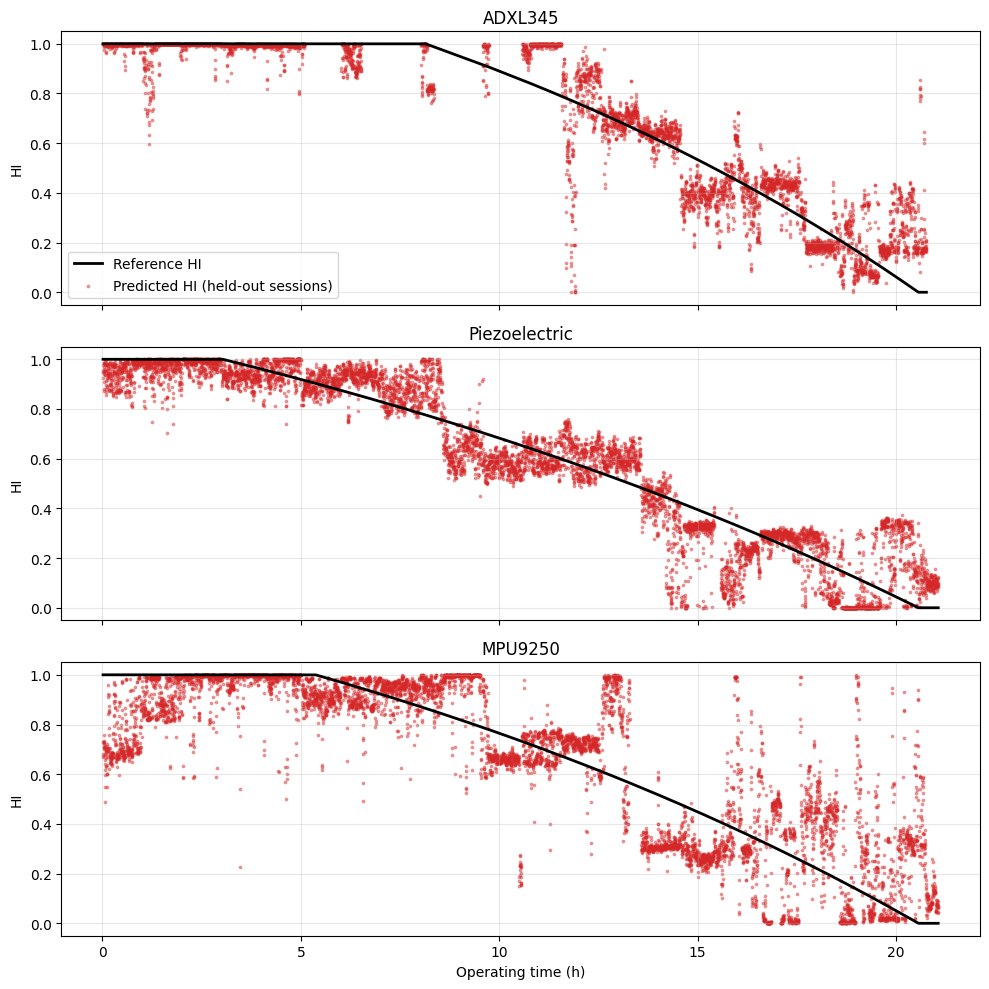

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
for ax, (s, name) in zip(axes, SENSORS.items()):
    d = pd.read_csv(RES / f"loso_{s}_pred.csv")
    h = d["t_s"] / 3600
    ax.plot(h, d["hi_true"], color="black", lw=2, label="Reference HI")
    ax.scatter(h, d["hi_pred"], s=3, color="tab:red", alpha=0.4, label="Predicted HI (held-out sessions)")
    ax.set_title(name); ax.set_ylabel("HI"); ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.3)
axes[0].legend(loc="lower left"); axes[-1].set_xlabel("Operating time (h)")
plt.tight_layout()

## Table 5.6 - calibration of the thresholds

Target RUL = time to act (3.6 h) + the 95th percentile of the optimistic RUL error on the
test sequences with a real RUL between 2.5 and 7 h (minimum margin 15 min).

In [6]:
th = json.loads((RES / "thresholds.json").read_text())
pd.DataFrame({SENSORS[s]: {"L (h)": v["L_h"], "test sequences in zone": v["n_zone"],
                           "mean error (min)": 60 * v["bias_h"], "MAE (min)": 60 * v["mae_h"],
                           "margin q95 (min)": 60 * v["options"]["q95"]["margin_h"],
                           "target RUL (h)": v["options"]["q95"]["rul_target_h"],
                           "equivalent HI threshold": v["options"]["q95"]["hi_threshold"]}
              for s, v in th["sensors"].items()}).T.round(3)

,L (h),test sequences in zone,mean error (min),MAE (min),margin q95 (min),target RUL (h),equivalent HI threshold
ADXL345,12.427,51.0,4.465,20.023,51.937,4.466,0.441
Piezoelectric,17.527,53.0,-9.967,15.397,20.056,3.934,0.288
MPU9250,15.189,57.0,-1.238,27.646,61.731,4.629,0.381


## Section 7.2 - RUL error in the decision zone, with whole sessions held out

The margins above come from the block split. With whole sessions held out, the error in the
decision zone is much larger than those margins.

In [7]:
def hi_to_rul(hi, L):
    return (1.0 - np.log2(2.0 - np.clip(hi, 0, 1))) * L

out = {}
for s, name in SENSORS.items():
    d = pd.read_csv(RES / f"loso_{s}_pred.csv")
    info = json.loads((RES / f"label_info_{s}.json").read_text())
    L_s, t_eol = info["L_s"], info["t_eol_s"]
    rul_true = (t_eol - d["t_s"]) / 3600
    rul_pred = hi_to_rul(d["hi_pred"].values, L_s) / 3600
    z = (rul_true >= 2.5) & (rul_true <= 7) & (d["hi_true"] < 1)
    e = rul_pred[z] - rul_true[z]
    out[name] = {"n": int(z.sum()), "MAE (h)": np.abs(e).mean(), "p95 optimistic error (h)": np.quantile(e, 0.95),
                 "margin from block split (h)": th["sensors"][s]["options"]["q95"]["margin_h"]}
pd.DataFrame(out).T.round(2)

,n,MAE (h),p95 optimistic error (h),margin from block split (h)
ADXL345,1584.0,1.00,1.39,0.87
Piezoelectric,1539.0,1.41,1.21,0.33
MPU9250,1563.0,2.47,4.43,1.03


## Hyperparameter optimization (Table 5.4)

ADXL345        best validation MSE 0.00133 (trial 18)
Piezoelectric  best validation MSE 0.00286 (trial 25)
MPU9250        best validation MSE 0.01075 (trial 28)


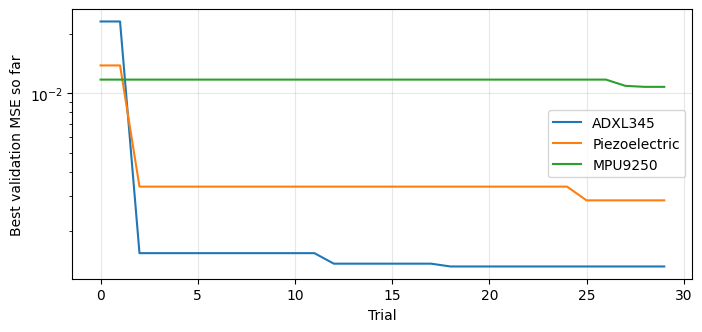

In [8]:
for s, name in SENSORS.items():
    o = pd.read_csv(RES / f"optuna_trials_{s}.csv")
    best = o.loc[o["value"].idxmin()]
    print(f"{name:<14} best validation MSE {best['value']:.5f} (trial {int(best['number'])})")
fig, ax = plt.subplots(figsize=(8, 3.5))
for s, name in SENSORS.items():
    o = pd.read_csv(RES / f"optuna_trials_{s}.csv")
    ax.plot(o["number"], o["value"].cummin(), label=name)
ax.set_xlabel("Trial"); ax.set_ylabel("Best validation MSE so far"); ax.set_yscale("log"); ax.legend(); ax.grid(alpha=0.3)

## Optional - load a trained model (requires PyTorch)

Running the model on the test sequences additionally requires the dataset and the
outputs of steps 1-5 of the pipeline (`data/processed/`).

In [9]:
try:
    import sys, torch
    sys.path.insert(0, str(ROOT / "prognostics"))
    from model_common import CNN_BiLSTM
    ck = torch.load(ROOT / "models" / "model_piezo.pt", map_location="cpu", weights_only=False)
    hp = ck["hparams"]
    model = CNN_BiLSTM(ck["input_dim"], hp["cnn_filters"], hp["cnn_kernel"],
                       hp["lstm_hidden"], hp["lstm_layers"], hp["dropout_rate"])
    model.load_state_dict(ck["model_state_dict"]); model.eval()
    print(model)
    print("features:", ck["feature_cols"])
    print("labels:", ck["label_info"])
except ImportError:
    print("PyTorch is not installed; skipping.")

PyTorch is not installed; skipping.
